In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [2]:
E = pd.read_csv("employees.csv")
E.info()
print(E.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    object 
 1   Gender             855 non-null    object 
 2   Start Date         1000 non-null   object 
 3   Last Login Time    1000 non-null   object 
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    object 
dtypes: float64(1), int64(1), object(6)
memory usage: 62.6+ KB
  First Name  Gender Start Date Last Login Time  Salary  Bonus %  \
0    Douglas    Male   8/6/1993        12:42 PM   97308    6.945   
1     Thomas    Male  3/31/1996         6:53 AM   61933    4.170   
2      Maria  Female  4/23/1993        11:17 AM  130590   11.858   
3      Jerry    Male   3/4/2005         1:00 PM  138705    9.340   
4      Larry

In [3]:
print(E.isna().sum())

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


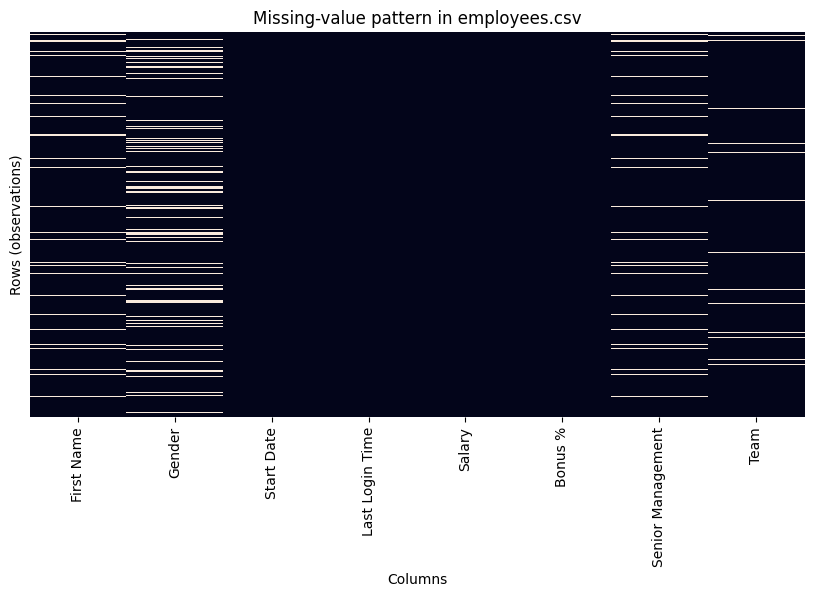

In [4]:
plt.figure(figsize=(10, 5))
sns.heatmap(E.isna(), cbar=False, yticklabels=False)
plt.title("Missing-value pattern in employees.csv")
plt.xlabel("Columns")
plt.ylabel("Rows (observations)")
plt.show()

In [5]:
E_copy = E.copy()
new_row = {
    "First Name": "-",
    "Gender": "na",
    "Start Date": np.nan,
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan,
}

In [6]:
E_copy = pd.concat([E_copy, pd.DataFrame([new_row])], ignore_index=True)

In [7]:
print(E_copy.isna().sum())
print("First Name == '-':", (E_copy["First Name"] == "-").sum())
print("Gender == 'na'   :", (E_copy["Gender"] == "na").sum())

First Name            67
Gender               145
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64
First Name == '-': 1
Gender == 'na'   : 1


In [10]:
''' `isna()` only recognises real missing values
(`np.nan`, `None`, `NaT`). `'-'` and `'na'` are ordinary strings, so pandas treats them
as valid data. (`read_csv` only converts a fixed list of strings such as `''`, `'NA'`,
`'NaN'`, `'null'` when reading, and `'-'` / lowercase `'na'` are not in it.) '''

" `isna()` only recognises real missing values\n(`np.nan`, `None`, `NaT`). `'-'` and `'na'` are ordinary strings, so pandas treats them\nas valid data. (`read_csv` only converts a fixed list of strings such as `''`, `'NA'`,\n`'NaN'`, `'null'` when reading, and `'-'` / lowercase `'na'` are not in it.) "

In [11]:
markers = {"-", "na", "n/a", ""}
for col in E_copy.select_dtypes(exclude="number").columns:
    mask = E_copy[col].astype(str).str.strip().str.lower().isin(markers)
    E_copy.loc[mask, col] = np.nan

In [12]:
print(E_copy.isna().sum())

First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


In [13]:
train, test = train_test_split(E_copy, test_size=0.2, random_state=42)
train_imp, test_imp = train.copy(), test.copy()

In [14]:
cat_cols = ["Gender", "Senior Management", "Team"]

In [15]:
num_cols = ["Salary", "Bonus %"]

In [16]:
cat_imp = SimpleImputer(strategy="most_frequent")
num_imp = SimpleImputer(strategy="median")

In [17]:
train_imp[cat_cols] = cat_imp.fit_transform(train[cat_cols])
test_imp[cat_cols] = cat_imp.transform(test[cat_cols])

In [18]:
train_imp[num_cols] = num_imp.fit_transform(train[num_cols])
test_imp[num_cols] = num_imp.transform(test[num_cols])

In [19]:
before = E_copy.isna().sum()
after = pd.concat([train_imp, test_imp]).isna().sum()
print(pd.DataFrame({"before": before, "after": after}))

                   before  after
First Name             68     68
Gender                146      0
Start Date              1      1
Last Login Time         1      1
Salary                  1      0
Bonus %                 1      0
Senior Management      68      0
Team                   44      0


In [20]:
''' it invents values so it can hide the real reason data is
missing, the median/mode shrinks the variance and can distort correlations, it adds bias
if values are not missing at random, and it cannot recover identifiers or dates
meaningfully always fit the imputer on training data only, then reuse it on test data '''

' it invents values so it can hide the real reason data is\nmissing, the median/mode shrinks the variance and can distort correlations, it adds bias\nif values are not missing at random, and it cannot recover identifiers or dates\nmeaningfully always fit the imputer on training data only, then reuse it on test data '